In [28]:
from pathlib import Path
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import StandardScaler

import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

warnings.filterwarnings("ignore")

torch.backends.cudnn.enabled = False

# =========================
# Reproducibility
# =========================
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)


# =========================
# GPU
# =========================
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch:", torch.__version__)
print("HIP:", torch.version.hip)
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "GPU not detected. Check ROCm environment."
    )

PyTorch: 2.9.1+rocm7.2.1
HIP: 7.2.53211-158bd99533
Device: cuda
GPU: AMD Radeon RX 9070 XT


In [5]:
# =========================
# Paths
# =========================
ROOT = Path(".")

DATA_DIR = ROOT / "data"
OUTPUT_DIR = ROOT / "outputs"

OUTPUT_DIR.mkdir(exist_ok=True)


TRAIN_PATH = DATA_DIR / "train.csv"
TEST_PATH = DATA_DIR / "test.csv"
SAMPLE_PATH = DATA_DIR / "sample_submission.csv"

# =========================
# Load
# =========================
train = pd.read_csv(TRAIN_PATH)
test = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_PATH)


TIME_COL = "id"

TARGETS = [
    col for col in sample_submission.columns
    if col != TIME_COL
]

HORIZON = 504
SEASONAL_LAG = 168
LOOKBACK = 168


train[TIME_COL] = pd.to_datetime(train[TIME_COL])
test[TIME_COL] = pd.to_datetime(test[TIME_COL])


train = (
    train
    .sort_values(TIME_COL)
    .reset_index(drop=True)
)

test = (
    test
    .sort_values(TIME_COL)
    .reset_index(drop=True)
)


print("Targets:", TARGETS)

print("Train:", train.shape)
print("Test:", test.shape)

print(
    "Train period:",
    train[TIME_COL].min(),
    "→",
    train[TIME_COL].max()
)

print(
    "Test period:",
    test[TIME_COL].min(),
    "→",
    test[TIME_COL].max()
)

Targets: ['valeur_NO2', 'valeur_CO', 'valeur_O3', 'valeur_PM10', 'valeur_PM25']
Train: (40991, 6)
Test: (504, 1)
Train period: 2020-01-01 00:00:00 → 2024-09-03 22:00:00
Test period: 2024-09-03 23:00:00 → 2024-09-24 22:00:00


In [6]:
print("Missing values:")
display(train[TARGETS].isna().sum())


print("Duplicate timestamps:")
print(train[TIME_COL].duplicated().sum())


print("Statistics:")
display(train[TARGETS].describe())


print("Timestamp frequency:")
display(
    train[TIME_COL]
    .diff()
    .value_counts()
    .head()
)

Missing values:


valeur_NO2      3297
valeur_CO      12529
valeur_O3        693
valeur_PM10     7167
valeur_PM25     1791
dtype: int64

Duplicate timestamps:
0
Statistics:


,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
count,37694.000000,28462.000000,40298.000000,33824.000000,39200.000000
mean,21.831528,0.200710,50.574349,18.221523,11.051161
std,14.658381,0.103691,26.488626,11.282385,8.151742
min,1.100000,0.037000,-1.900000,0.500000,0.000000
25%,11.300000,0.145000,33.000000,10.700000,5.800000
50%,17.600000,0.177000,50.700000,15.600000,8.700000
75%,28.200000,0.226000,66.600000,22.900000,13.600000
max,131.000000,4.309000,193.100000,128.500000,111.100000


Timestamp frequency:


id
0 days 01:00:00    40990
Name: count, dtype: int64

In [7]:
def count_iqr_outliers(series):
    x = series.dropna()

    q1 = x.quantile(0.25)
    q3 = x.quantile(0.75)

    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return ((x < lower) | (x > upper)).sum()


outliers = {
    col: count_iqr_outliers(train[col])
    for col in TARGETS
}

display(
    pd.Series(
        outliers,
        name="IQR outliers"
    )
)

valeur_NO2     1646
valeur_CO      1606
valeur_O3       587
valeur_PM10    1386
valeur_PM25    2396
Name: IQR outliers, dtype: int64

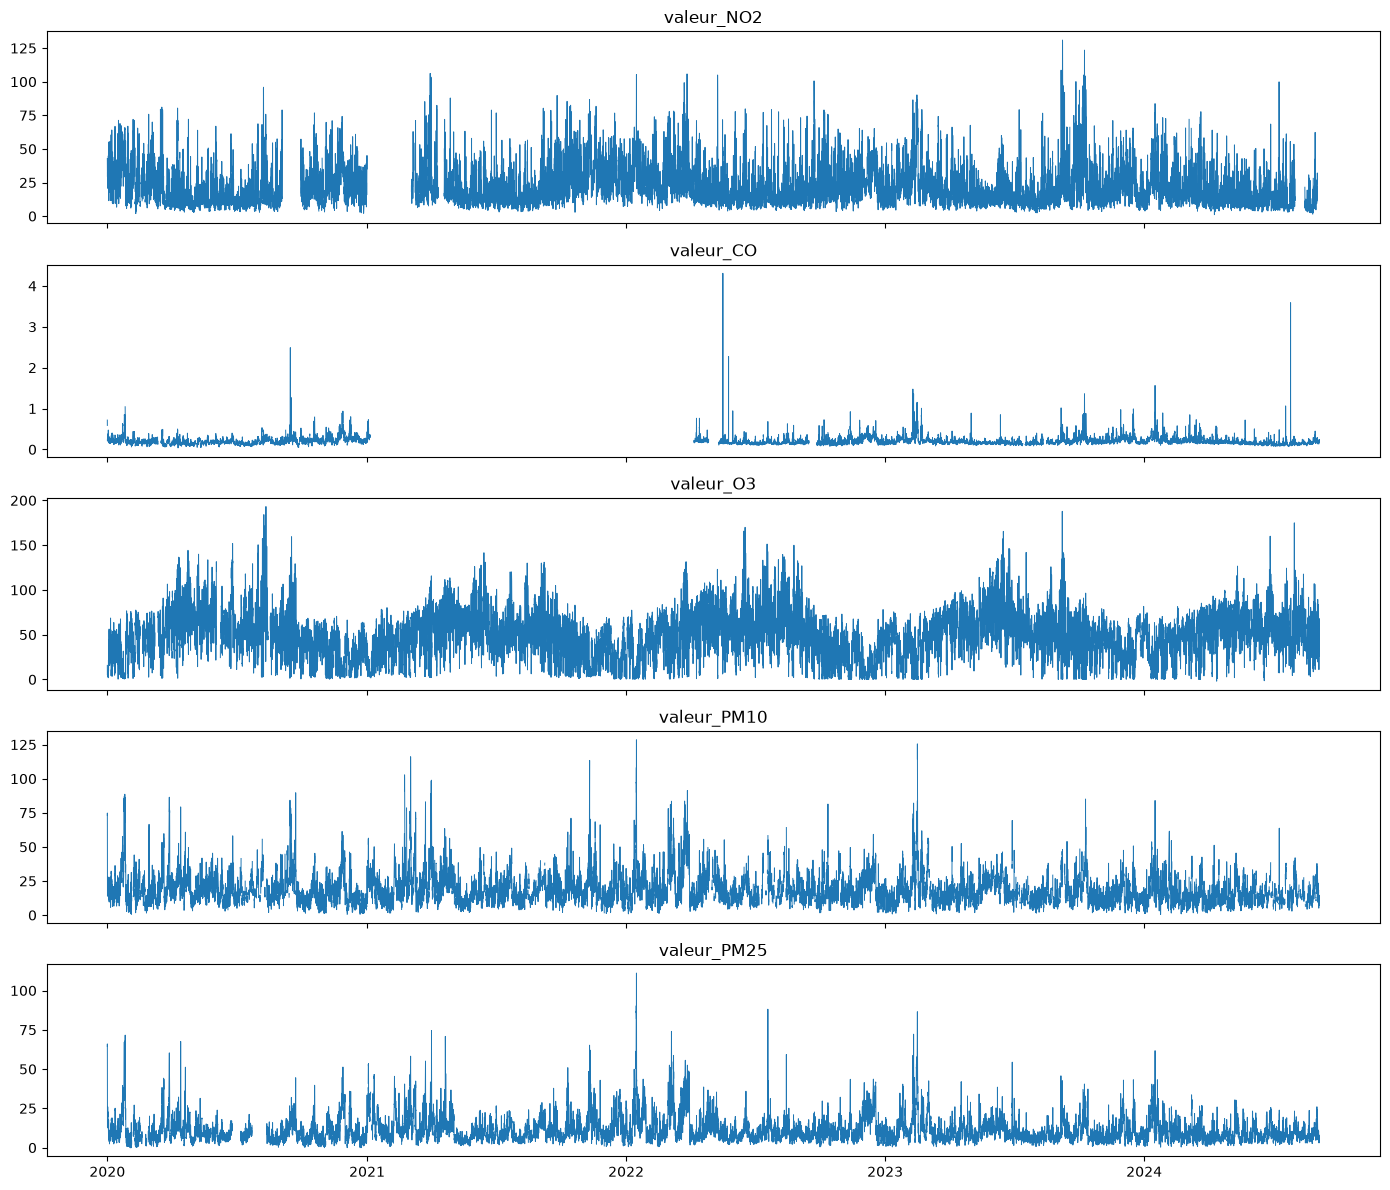

In [8]:
fig, axes = plt.subplots(
    len(TARGETS),
    1,
    figsize=(14, 12),
    sharex=True
)

for ax, col in zip(axes, TARGETS):

    ax.plot(
        train[TIME_COL],
        train[col],
        linewidth=0.7
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()

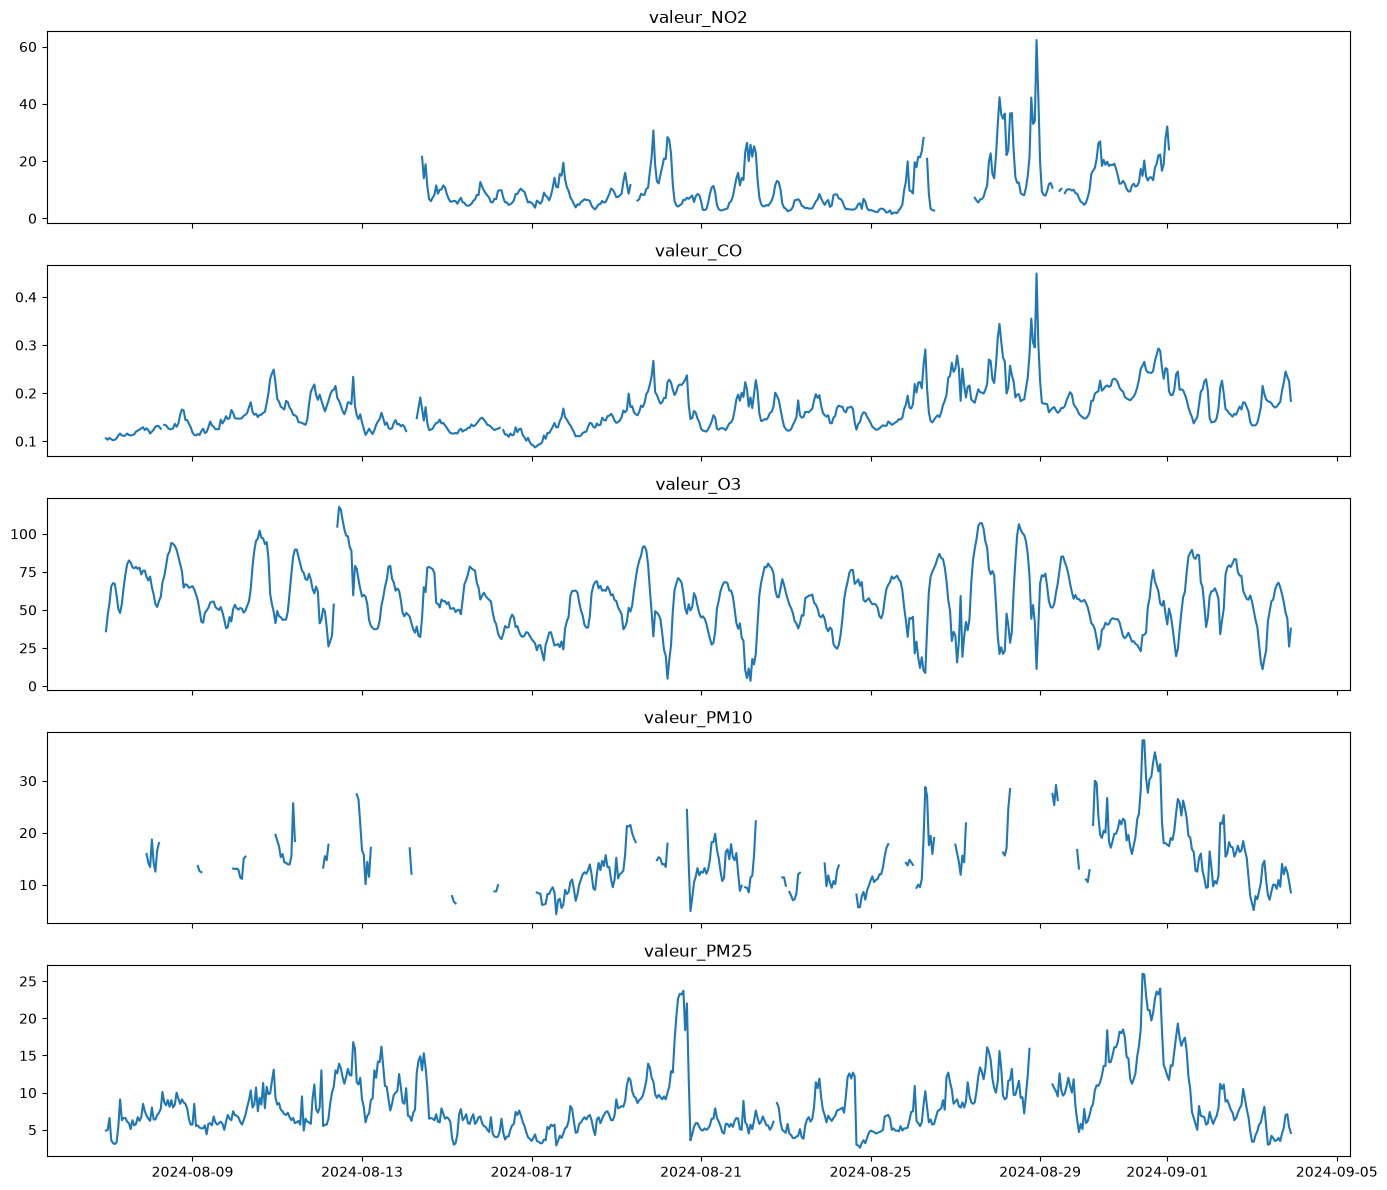

In [9]:
recent = train.iloc[-24 * 28:]

fig, axes = plt.subplots(
    len(TARGETS),
    1,
    figsize=(14, 12),
    sharex=True
)

for ax, col in zip(axes, TARGETS):

    ax.plot(
        recent[TIME_COL],
        recent[col]
    )

    ax.set_title(col)

plt.tight_layout()
plt.show()

In [10]:
eda = train.copy()

eda["hour"] = eda[TIME_COL].dt.hour
eda["weekday"] = eda[TIME_COL].dt.dayofweek


hourly_profile = (
    eda
    .groupby("hour")[TARGETS]
    .mean()
)

weekly_profile = (
    eda
    .groupby("weekday")[TARGETS]
    .mean()
)

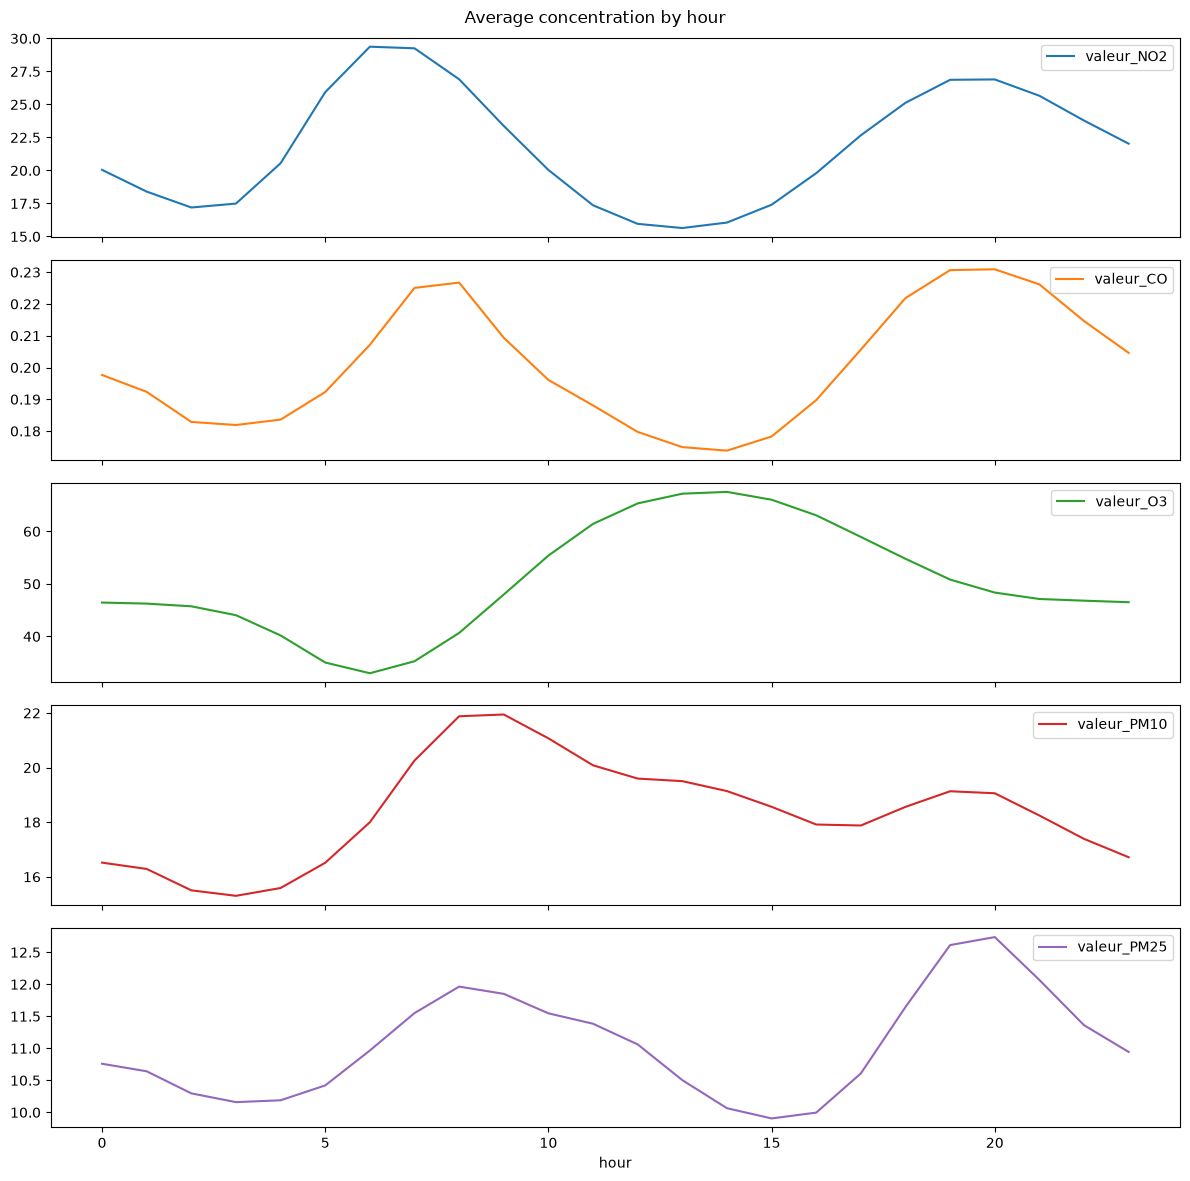

In [11]:
hourly_profile.plot(
    subplots=True,
    figsize=(12, 12),
    title="Average concentration by hour"
)

plt.tight_layout()
plt.show()

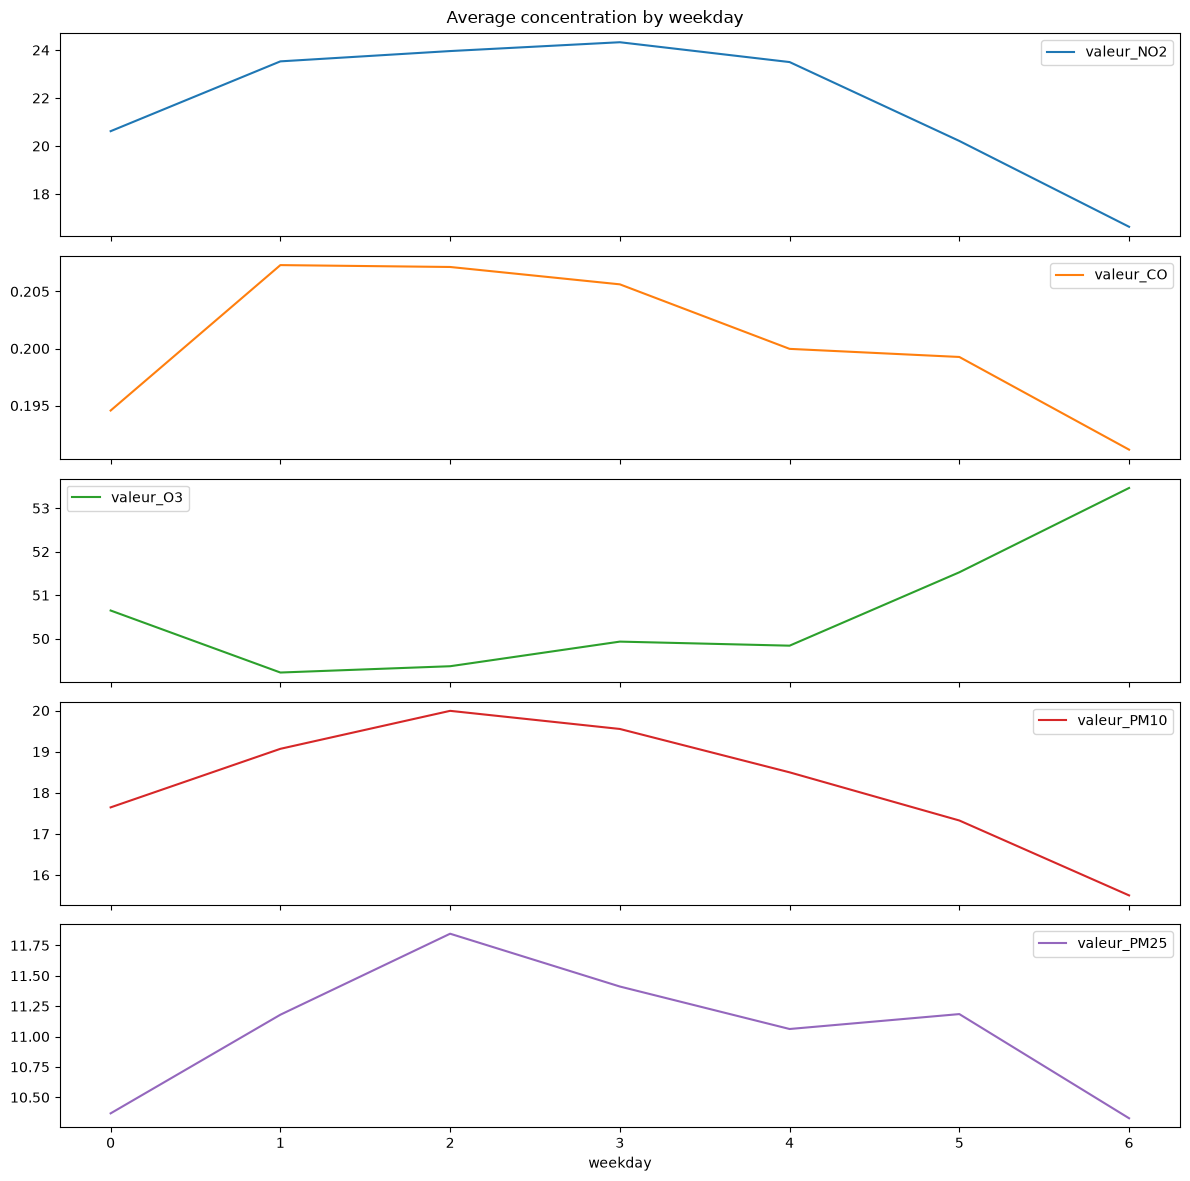

In [12]:
weekly_profile.plot(
    subplots=True,
    figsize=(12, 12),
    title="Average concentration by weekday"
)

plt.tight_layout()
plt.show()

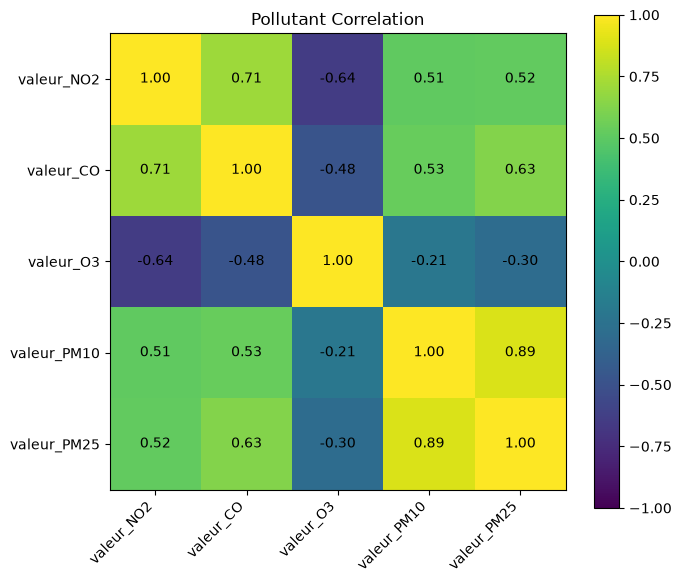

In [13]:
corr = train[TARGETS].corr()

fig, ax = plt.subplots(figsize=(7, 6))

im = ax.imshow(
    corr,
    vmin=-1,
    vmax=1
)

ax.set_xticks(range(len(TARGETS)))
ax.set_yticks(range(len(TARGETS)))

ax.set_xticklabels(
    TARGETS,
    rotation=45,
    ha="right"
)

ax.set_yticklabels(TARGETS)


for i in range(len(TARGETS)):
    for j in range(len(TARGETS)):
        ax.text(
            j,
            i,
            f"{corr.iloc[i, j]:.2f}",
            ha="center",
            va="center"
        )


plt.colorbar(im)
plt.title("Pollutant Correlation")
plt.tight_layout()
plt.show()

In [14]:
train_raw = train.iloc[:-HORIZON].copy()
val = train.iloc[-HORIZON:].copy()


print(
    "Training:",
    train_raw[TIME_COL].min(),
    "→",
    train_raw[TIME_COL].max()
)

print(
    "Validation:",
    val[TIME_COL].min(),
    "→",
    val[TIME_COL].max()
)

print("Validation length:", len(val))

Training: 2020-01-01 00:00:00 → 2024-08-13 22:00:00
Validation: 2024-08-13 23:00:00 → 2024-09-03 22:00:00
Validation length: 504


In [15]:
train_model = train_raw.copy()

training_median = (
    train_model[TARGETS]
    .median()
)


train_model[TARGETS] = (
    train_model[TARGETS]
    .ffill()
    .fillna(training_median)
)


print(
    train_model[TARGETS]
    .isna()
    .sum()
)

valeur_NO2     0
valeur_CO      0
valeur_O3      0
valeur_PM10    0
valeur_PM25    0
dtype: int64


In [16]:
def evaluate(y_true_df, pred):
    scores = {}

    for i, col in enumerate(TARGETS):

        actual = y_true_df[col].to_numpy()
        forecast = pred[:, i]

        mask = ~np.isnan(actual)

        scores[col] = mean_absolute_error(
            actual[mask],
            forecast[mask]
        )

    scores["Average"] = np.mean(
        [scores[col] for col in TARGETS]
    )

    return scores


def non_negative(pred):
    return np.maximum(pred, 0)

In [17]:
def persistence_forecast(history, horizon):

    last_values = (
        history[TARGETS]
        .iloc[-1]
        .to_numpy()
    )

    return np.tile(
        last_values,
        (horizon, 1)
    )


persistence_pred = persistence_forecast(
    train_model,
    HORIZON
)

persistence_pred = non_negative(
    persistence_pred
)


print(
    evaluate(
        val,
        persistence_pred
    )
)

{'valeur_NO2': 7.428680203045685, 'valeur_CO': 0.04580722891566265, 'valeur_O3': 16.159920634920635, 'valeur_PM10': 5.622408026755854, 'valeur_PM25': 4.236659877800407, 'Average': np.float64(6.698695194287649)}


In [18]:
def seasonal_naive_forecast(
    history,
    horizon,
    lag=168
):

    season = (
        history[TARGETS]
        .iloc[-lag:]
        .to_numpy()
    )

    repeats = int(
        np.ceil(horizon / lag)
    )

    pred = np.tile(
        season,
        (repeats, 1)
    )

    return pred[:horizon]


seasonal_pred = seasonal_naive_forecast(
    train_model,
    HORIZON,
    SEASONAL_LAG
)

seasonal_pred = non_negative(
    seasonal_pred
)


print(
    evaluate(
        val,
        seasonal_pred
    )
)

{'valeur_NO2': 7.428680203045685, 'valeur_CO': 0.04449397590361446, 'valeur_O3': 17.28988095238095, 'valeur_PM10': 6.044147157190635, 'valeur_PM25': 3.554989816700611, 'Average': np.float64(6.872438421044299)}


In [20]:
from chronos import BaseChronosPipeline


print(
    "Chronos will run on:",
    torch.cuda.get_device_name(0)
)


chronos = (
    BaseChronosPipeline
    .from_pretrained(
        "amazon/chronos-2",
        device_map="cuda"
    )
)


CHRONOS_CONTEXT = 2048


print("Model: amazon/chronos-2")
print("Hardware:", torch.cuda.get_device_name(0))
print("Context length:", CHRONOS_CONTEXT)
print("Prediction length:", HORIZON)
print("Forecast quantile: 0.5")

Chronos will run on: AMD Radeon RX 9070 XT


config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  478MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Model: amazon/chronos-2
Hardware: AMD Radeon RX 9070 XT
Context length: 2048
Prediction length: 504
Forecast quantile: 0.5


In [21]:
def chronos_independent_forecast(
    history,
    horizon
):

    inputs = []

    for col in TARGETS:

        x = (
            history[col]
            .to_numpy(dtype=np.float32)
        )

        x = x[-CHRONOS_CONTEXT:]

        inputs.append(x)


    quantiles, _ = (
        chronos.predict_quantiles(
            inputs=inputs,
            prediction_length=horizon,
            quantile_levels=[0.5],
            context_length=CHRONOS_CONTEXT
        )
    )


    predictions = []

    for q in quantiles:

        q = q.cpu().numpy()

        # n_variates=1 × horizon × quantile
        predictions.append(
            q[0, :, 0]
        )


    return np.column_stack(
        predictions
    )


chronos_ind_pred = (
    chronos_independent_forecast(
        train_model,
        HORIZON
    )
)

chronos_ind_pred = non_negative(
    chronos_ind_pred
)


print(
    evaluate(
        val,
        chronos_ind_pred
    )
)

{'valeur_NO2': 7.20560242657734, 'valeur_CO': 0.04629068982122414, 'valeur_O3': 12.970214023287333, 'valeur_PM10': 5.054452942047629, 'valeur_PM25': 3.228392590718939, 'Average': np.float64(5.700990534490493)}


In [22]:
def chronos_joint_forecast(
    history,
    horizon
):

    x = (
        history[TARGETS]
        .iloc[-CHRONOS_CONTEXT:]
        .to_numpy(dtype=np.float32)
        .T
    )

    # shape:
    # pollutants × time


    quantiles, _ = (
        chronos.predict_quantiles(
            inputs=[x],
            prediction_length=horizon,
            quantile_levels=[0.5],
            context_length=CHRONOS_CONTEXT
        )
    )


    q = (
        quantiles[0]
        .cpu()
        .numpy()
    )

    # pollutants × horizon × quantile

    pred = q[:, :, 0].T

    # horizon × pollutants

    return pred


chronos_joint_pred = (
    chronos_joint_forecast(
        train_model,
        HORIZON
    )
)

chronos_joint_pred = non_negative(
    chronos_joint_pred
)


print(
    evaluate(
        val,
        chronos_joint_pred
    )
)

{'valeur_NO2': 7.450749664500281, 'valeur_CO': 0.04060061606980232, 'valeur_O3': 13.105554409632608, 'valeur_PM10': 5.314983041948299, 'valeur_PM25': 3.359051127540604, 'Average': np.float64(5.854187771938319)}


In [23]:
class SimpleLSTM(nn.Module):

    def __init__(
        self,
        n_features,
        hidden_size=64
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=n_features,
            hidden_size=hidden_size,
            batch_first=True
        )

        self.fc = nn.Linear(
            hidden_size,
            n_features
        )


    def forward(self, x):

        output, _ = self.lstm(x)

        last = output[:, -1, :]

        return self.fc(last)

In [24]:
def make_sequences(
    data,
    lookback
):

    X = []
    y = []

    for i in range(
        lookback,
        len(data)
    ):

        X.append(
            data[i-lookback:i]
        )

        y.append(
            data[i]
        )

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

In [32]:
def train_lstm(
    history,
    lookback=168,
    epochs=10
):

    scaler = StandardScaler()

    data_scaled = scaler.fit_transform(
        history[TARGETS]
    ).astype(np.float32)


    X, y = make_sequences(
        data_scaled,
        lookback
    )


    X_tensor = torch.tensor(X)
    y_tensor = torch.tensor(y)


    dataset = TensorDataset(
        X_tensor,
        y_tensor
    )


    loader = DataLoader(
        dataset,
        batch_size=1024,
        shuffle=True
    )


    model = SimpleLSTM(
        n_features=len(TARGETS),
        hidden_size=128
    ).to(DEVICE)


    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=1e-3
    )

    loss_fn = nn.L1Loss()


    for epoch in range(epochs):

        model.train()

        total_loss = 0


        for xb, yb in loader:

            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)


            optimizer.zero_grad()


            pred = model(xb)


            loss = loss_fn(
                pred,
                yb
            )


            loss.backward()

            optimizer.step()


            total_loss += (
                loss.item()
                * len(xb)
            )


        epoch_loss = (
            total_loss
            / len(dataset)
        )


        print(
            f"Epoch {epoch+1:02d} "
            f"| MAE loss: {epoch_loss:.4f}"
        )


    return model, scaler

In [33]:
lstm_model, lstm_scaler = train_lstm(
    train_model,
    LOOKBACK,
    epochs=10
)

Epoch 01 | MAE loss: 0.5417
Epoch 02 | MAE loss: 0.3263
Epoch 03 | MAE loss: 0.2319
Epoch 04 | MAE loss: 0.1983
Epoch 05 | MAE loss: 0.1847
Epoch 06 | MAE loss: 0.1782
Epoch 07 | MAE loss: 0.1735
Epoch 08 | MAE loss: 0.1707
Epoch 09 | MAE loss: 0.1691
Epoch 10 | MAE loss: 0.1681


In [34]:
@torch.no_grad()
def lstm_forecast(
    model,
    scaler,
    history,
    horizon,
    lookback
):

    model.eval()


    scaled = scaler.transform(
        history[TARGETS]
    ).astype(np.float32)


    window = scaled[-lookback:].copy()

    forecasts = []


    for _ in range(horizon):

        x = torch.tensor(
            window,
            dtype=torch.float32
        )

        x = (
            x.unsqueeze(0)
            .to(DEVICE)
        )


        next_value = (
            model(x)
            .cpu()
            .numpy()[0]
        )


        forecasts.append(
            next_value
        )


        window = np.vstack([
            window[1:],
            next_value
        ])


    forecasts = np.array(
        forecasts
    )


    forecasts = scaler.inverse_transform(
        forecasts
    )


    return forecasts

In [35]:
lstm_pred = lstm_forecast(
    lstm_model,
    lstm_scaler,
    train_model,
    HORIZON,
    LOOKBACK
)

lstm_pred = non_negative(
    lstm_pred
)


print(
    evaluate(
        val,
        lstm_pred
    )
)

{'valeur_NO2': 27.092711369277257, 'valeur_CO': 0.15264592287028173, 'valeur_O3': 34.96301173179869, 'valeur_PM10': 19.868835224036786, 'valeur_PM25': 18.496885904323786, 'Average': np.float64(20.11481803046136)}


In [36]:
predictions = {
    "Persistence": persistence_pred,
    "Seasonal Naive": seasonal_pred,
    "Chronos Independent": chronos_ind_pred,
    "Chronos Joint": chronos_joint_pred,
    "LSTM": lstm_pred
}


results = {}


for name, pred in predictions.items():

    results[name] = evaluate(
        val,
        pred
    )


results_df = (
    pd.DataFrame(results)
    .T
    .sort_values("Average")
)


display(
    results_df.round(4)
)


results_df.to_csv(
    OUTPUT_DIR / "validation_results.csv"
)

,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25,Average
Chronos Independent,7.2056,0.0463,12.9702,5.0545,3.2284,5.7010
Chronos Joint,7.4507,0.0406,13.1056,5.3150,3.3591,5.8542
Persistence,7.4287,0.0458,16.1599,5.6224,4.2367,6.6987
Seasonal Naive,7.4287,0.0445,17.2899,6.0441,3.5550,6.8724
LSTM,27.0927,0.1526,34.9630,19.8688,18.4969,20.1148


In [37]:
horizon_results = []


for model_name, pred in predictions.items():

    for week in range(3):

        start = week * 168
        end = (week + 1) * 168


        score = evaluate(
            val.iloc[start:end],
            pred[start:end]
        )


        horizon_results.append({
            "Model": model_name,
            "Week": week + 1,
            "Average_MAE": score["Average"]
        })


horizon_df = pd.DataFrame(
    horizon_results
)


horizon_table = (
    horizon_df
    .pivot(
        index="Model",
        columns="Week",
        values="Average_MAE"
    )
)


horizon_table.columns = [
    "Week 1",
    "Week 2",
    "Week 3"
]


display(
    horizon_table.round(4)
)

,Week 1,Week 2,Week 3
Model,,,
Chronos Independent,5.3263,5.4494,6.2699
Chronos Joint,5.3748,5.7967,6.3539
LSTM,7.6596,22.0397,29.5511
Persistence,6.3346,6.9690,6.8081
Seasonal Naive,6.5659,6.7041,7.3051


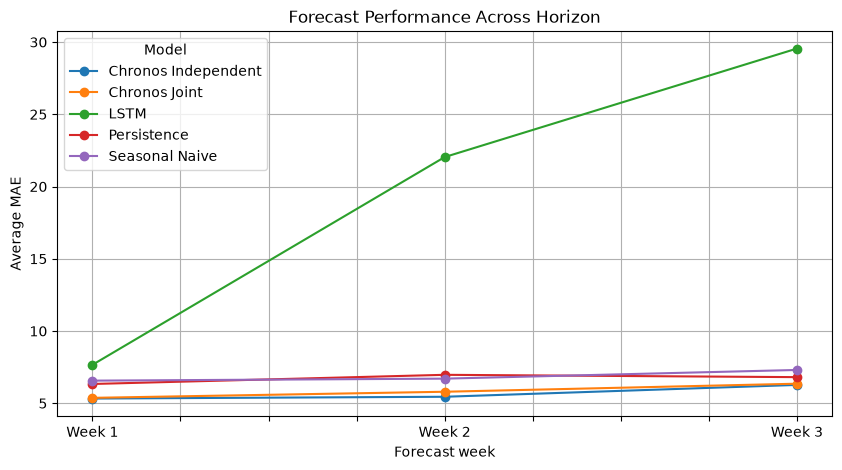

In [38]:
horizon_table.T.plot(
    marker="o",
    figsize=(10, 5)
)

plt.xlabel("Forecast week")
plt.ylabel("Average MAE")

plt.title(
    "Forecast Performance Across Horizon"
)

plt.grid()
plt.show()

In [39]:
best_model_name = results_df.index[0]

best_pred = predictions[
    best_model_name
]


print(
    "Best model:",
    best_model_name
)

Best model: Chronos Independent


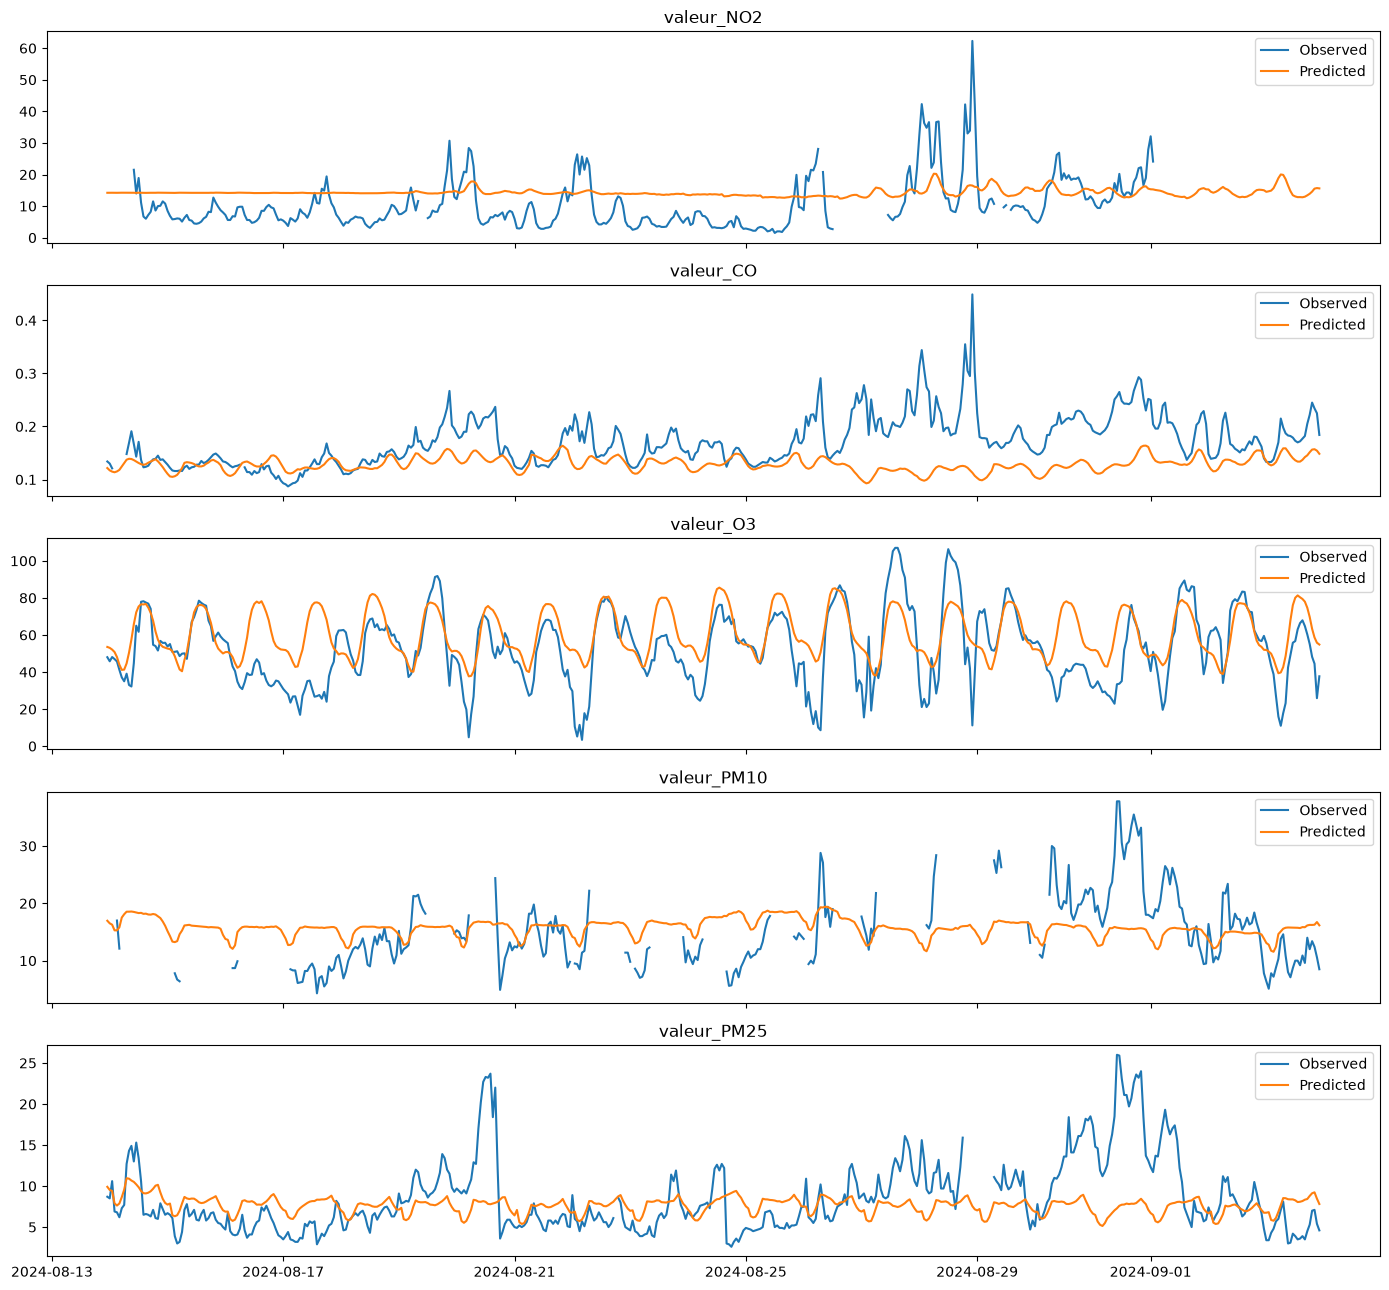

In [40]:
fig, axes = plt.subplots(
    len(TARGETS),
    1,
    figsize=(14, 13),
    sharex=True
)


for i, (ax, col) in enumerate(
    zip(axes, TARGETS)
):

    ax.plot(
        val[TIME_COL],
        val[col],
        label="Observed"
    )

    ax.plot(
        val[TIME_COL],
        best_pred[:, i],
        label="Predicted"
    )

    ax.set_title(col)
    ax.legend()


plt.tight_layout()
plt.show()

In [41]:
comparison = pd.DataFrame({
    "Seasonal Naive":
        pd.Series(
            evaluate(val, seasonal_pred)
        ),

    "Chronos Independent":
        pd.Series(
            evaluate(val, chronos_ind_pred)
        ),

    "Chronos Joint":
        pd.Series(
            evaluate(val, chronos_joint_pred)
        )
})


comparison["Joint - Seasonal"] = (
    comparison["Chronos Joint"]
    -
    comparison["Seasonal Naive"]
)


display(
    comparison.round(4)
)

,Seasonal Naive,Chronos Independent,Chronos Joint,Joint - Seasonal
valeur_NO2,7.4287,7.2056,7.4507,0.0221
valeur_CO,0.0445,0.0463,0.0406,-0.0039
valeur_O3,17.2899,12.9702,13.1056,-4.1843
valeur_PM10,6.0441,5.0545,5.3150,-0.7292
valeur_PM25,3.5550,3.2284,3.3591,-0.1959
Average,6.8724,5.7010,5.8542,-1.0183


In [42]:
full_train = train.copy()


full_median = (
    full_train[TARGETS]
    .median()
)


full_train[TARGETS] = (
    full_train[TARGETS]
    .ffill()
    .fillna(full_median)
)

In [43]:
if best_model_name == "Persistence":

    final_pred = persistence_forecast(
        full_train,
        HORIZON
    )


elif best_model_name == "Seasonal Naive":

    final_pred = seasonal_naive_forecast(
        full_train,
        HORIZON,
        SEASONAL_LAG
    )


elif best_model_name == "Chronos Independent":

    final_pred = chronos_independent_forecast(
        full_train,
        HORIZON
    )


elif best_model_name == "Chronos Joint":

    final_pred = chronos_joint_forecast(
        full_train,
        HORIZON
    )


elif best_model_name == "LSTM":

    final_lstm, final_scaler = train_lstm(
        full_train,
        LOOKBACK,
        epochs=10
    )

    final_pred = lstm_forecast(
        final_lstm,
        final_scaler,
        full_train,
        HORIZON,
        LOOKBACK
    )


else:

    raise ValueError(
        f"Unknown model: {best_model_name}"
    )


final_pred = non_negative(
    final_pred
)


print(
    final_pred.shape
)

(504, 5)


In [44]:
prediction_df = pd.DataFrame({
    TIME_COL: test[TIME_COL]
})


for i, col in enumerate(TARGETS):

    prediction_df[col] = (
        final_pred[:, i]
    )

In [45]:
submission = sample_submission.copy()


submission["_timestamp"] = pd.to_datetime(
    submission[TIME_COL]
)


prediction_df["_timestamp"] = pd.to_datetime(
    prediction_df[TIME_COL]
)


submission = (
    submission[
        [TIME_COL, "_timestamp"]
    ]
    .merge(
        prediction_df[
            ["_timestamp"] + TARGETS
        ],
        on="_timestamp",
        how="left"
    )
)


submission = submission[
    [TIME_COL] + TARGETS
]

In [46]:
assert len(submission) == len(test)

assert len(submission) == HORIZON

assert (
    submission[TARGETS]
    .isna()
    .sum()
    .sum()
    == 0
)


display(
    submission.head()
)


print(
    submission.shape
)

,id,valeur_NO2,valeur_CO,valeur_O3,valeur_PM10,valeur_PM25
0,2024-09-03 23,23.862431,0.169231,42.454582,8.395615,4.697102
1,2024-09-04 00,23.904072,0.160339,41.898544,8.548316,4.907578
2,2024-09-04 01,23.928728,0.155140,41.196236,8.370762,5.393845
3,2024-09-04 02,23.800312,0.153537,39.762848,7.988272,4.459916
4,2024-09-04 03,23.738028,0.156469,36.809376,7.962337,4.293939


(504, 6)


In [47]:
submission.to_csv(
    OUTPUT_DIR / "submission.csv",
    index=False
)

print(
    "Saved to:",
    OUTPUT_DIR / "submission.csv"
)

Saved to: outputs\submission.csv
